# 02 Terrain

**Purpose:** Load `data/processed/aoi.gpkg`, clip the DEM to it (`geo_utils.clip_raster_to_aoi`), then derive slope, aspect, curvature, SPI, TWI, and STI. Save each as its own COG in `data/processed/`. Use `richdem` or `whitebox` rather than manual QGIS raster algebra see docs/data_sources.md for DEM source options.

In [13]:
! pip install whitebox


[notice] A new release of pip is available: 26.0.1 -> 26.2
[notice] To update, run: C:\Users\PCC\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


### Importing libraries

In [1]:
import sys
from pathlib import Path

import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
import requests
import whitebox

sys.path.append("../src")
from landslide_lk import geo_utils

DATA_RAW = Path("../data/raw")
DATA_PROCESSED = Path("../data/processed")
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

### Load AOI and get bounding box for the DEM download

In [ ]:
aoi_path = DATA_PROCESSED / "aoi.gpkg"
assert aoi_path.exists(), "aoi.gpkg missing - run notebook 01 first"

aoi = gpd.read_file(aoi_path, layer="dissolved")
aoi_wgs84 = aoi.to_crs("EPSG:4326")  # OpenTopography API wants lat/lon

minx, miny, maxx, maxy = aoi_wgs84.total_bounds
print(f"Bounding box: {minx:.4f}, {miny:.4f}, {maxx:.4f}, {maxy:.4f}")


Bounding box: 79.8863, 6.2288, 81.2715, 7.6216


### Download the DEM

In [5]:
dem_raw_path = DATA_RAW / "dem_srtm30m_raw.tif"

if not dem_raw_path.exists():
    API_KEY = "0be87913007dcf8f6f0447c82b34d771"

    url = "https://portal.opentopography.org/API/globaldem"
    params = {
        "demtype": "SRTMGL1",
        "south": float(miny), "north": float(maxy),
        "west": float(minx), "east": float(maxx),
        "outputFormat": "GTiff",
        "API_Key": API_KEY,
    }
    r = requests.get(url, params=params)

    print("Status:", r.status_code)
    print("Content-Type:", r.headers.get("Content-Type"))

    # Check the actual TIFF magic bytes rather than the Content-Type header —
    # OpenTopography serves valid GeoTIFFs as application/octet-stream, not image/tiff
    is_tiff = r.content[:4] in (b"II*\x00", b"MM\x00*")
    assert r.status_code == 200 and is_tiff, (
        f"Download failed. First 200 bytes of response: {r.content[:200]}"
    )

    dem_raw_path.write_bytes(r.content)

print("Raw DEM ready:", dem_raw_path.exists(), f"({dem_raw_path.stat().st_size / 1e6:.1f} MB)")

Status: 200
Content-Type: application/octet-stream
Raw DEM ready: True (22.9 MB)


In [7]:
import rasterio

with rasterio.open(DATA_RAW / "dem_srtm30m_raw.tif") as src:
    print("Shape:", src.shape)
    try:
        test_read = src.read(1, window=((0, 10), (0, 10)))
        print("Small window read OK")
    except Exception as e:
        print("FAILED even on a small window:", e)

Shape: (5014, 4987)
Small window read OK


In [8]:
import rasterio
import numpy as np

with rasterio.open(DATA_RAW / "dem_srtm30m_raw.tif") as src:
    try:
        full = src.read(1)
        print("Full read succeeded:", full.shape)
        print("Any NaNs:", np.isnan(full).sum() if full.dtype.kind == 'f' else "N/A (int dtype)")
    except Exception as e:
        print("FAILED on full read:", e)

FAILED on full read: Read failed. See previous exception for details.


In [9]:
dem_raw_path = DATA_RAW / "dem_srtm30m_raw.tif"
if dem_raw_path.exists():
    dem_raw_path.unlink()
    print("Deleted corrupted file")

Deleted corrupted file


In [10]:
import shutil

API_KEY = "0be87913007dcf8f6f0447c82b34d771"
url = "https://portal.opentopography.org/API/globaldem"
params = {
    "demtype": "SRTMGL1",
    "south": float(miny), "north": float(maxy),
    "west": float(minx), "east": float(maxx),
    "outputFormat": "GTiff",
    "API_Key": API_KEY,
}

tmp_path = Path.home() / "dem_download_tmp.tif"

with requests.get(url, params=params, stream=True) as r:
    r.raise_for_status()
    with open(tmp_path, "wb") as f:
        for chunk in r.iter_content(chunk_size=1 << 20):  # 1MB chunks
            f.write(chunk)

print("Downloaded to temp:", tmp_path.stat().st_size / 1e6, "MB")

shutil.move(str(tmp_path), str(dem_raw_path))
print("Moved into place:", dem_raw_path.stat().st_size / 1e6, "MB")

Downloaded to temp: 27.237488 MB
Moved into place: 27.237488 MB


In [11]:
with rasterio.open(dem_raw_path) as src:
    full = src.read(1)
    print("Full read succeeded:", full.shape)
    print("Min/max elevation:", np.nanmin(full), np.nanmax(full))

Full read succeeded: (5014, 4987)
Min/max elevation: -16 2523


### clip to AOI

In [12]:
dem_clipped = DATA_PROCESSED / "dem.tif"

geo_utils.clip_raster_to_aoi(
    src_path=dem_raw_path,
    aoi=aoi_wgs84,
    dst_path=dem_clipped,
    dtype="float32",
)
assert dem_clipped.exists(), "clip step failed to write output"
print("Clipped DEM ready:", dem_clipped.exists())

Clipped DEM ready: True


### Checking whether full boundary exists

In [13]:
with rasterio.open(dem_clipped) as src:
    full = src.read(1)
    print("Shape:", full.shape)
    print("Min/max:", np.nanmin(full), np.nanmax(full))

Shape: (5014, 4987)
Min/max: -32768.0 2523.0


### Reproject to UTM 44N

In [14]:
dem_utm = DATA_PROCESSED / "dem_utm.tif"

geo_utils.reproject_raster(dem_clipped, dem_utm, dst_crs="EPSG:32644")
assert dem_utm.exists(), "reproject step failed to write output"
print("Reprojected DEM ready:", dem_utm.exists())

Reprojected DEM ready: True


### Set up whitebox with an absolute working directory

In [15]:
wbt = whitebox.WhiteboxTools()
wbt.set_working_dir(str(DATA_PROCESSED.resolve()))  # must be absolute, not relative
wbt.verbose = True

print("Working dir:", wbt.work_dir)
assert (DATA_PROCESSED / "dem_utm.tif").exists(), "dem_utm.tif not in working dir — check Cell 5"

Working dir: D:\PROJECTS\Landslide_prediction\data\processed


### Fill depressions (required before any flow-based calculation)

In [16]:
wbt.fill_depressions("dem_utm.tif", "dem_filled.tif")
assert (DATA_PROCESSED / "dem_filled.tif").exists(), (
    "fill_depressions failed — check the printed whitebox output above for the actual error"
)
print("dem_filled.tif ready")

.\whitebox_tools.exe --run="FillDepressions" --wd="D:\PROJECTS\Landslide_prediction\data\processed" --dem='dem_utm.tif' --output='dem_filled.tif' --fix_flats -v --compress_rasters=False

******************************
* Welcome to FillDepressions *
* Powered by WhiteboxTools   *
* www.whiteboxgeo.com        *
******************************
Reading data...
Finding pit cells: 12%
Finding pit cells: 25%
Finding pit cells: 37%
Finding pit cells: 50%
Finding pit cells: 62%
Finding pit cells: 75%
Finding pit cells: 87%
Finding pit cells: 100%
Filling depressions: 0%
Filling depressions: 1%
Filling depressions: 2%
Filling depressions: 3%
Filling depressions: 4%
Filling depressions: 5%
Filling depressions: 6%
Filling depressions: 7%
Filling depressions: 8%
Filling depressions: 9%
Filling depressions: 10%
Filling depressions: 11%
Filling depressions: 12%
Filling depressions: 13%
Filling depressions: 14%
Filling depressions: 15%
Filling depressions: 16%
Filling depressions: 17%
Filling depressio

### basic terrain attributes

In [17]:
wbt.slope("dem_filled.tif", "slope.tif")
assert (DATA_PROCESSED / "slope.tif").exists(), "slope failed"

wbt.aspect("dem_filled.tif", "aspect.tif")
assert (DATA_PROCESSED / "aspect.tif").exists(), "aspect failed"

print("slope.tif and aspect.tif ready")

.\whitebox_tools.exe --run="Slope" --wd="D:\PROJECTS\Landslide_prediction\data\processed" --dem='dem_filled.tif' --output='slope.tif' --units=degrees -v --compress_rasters=False

****************************
* Welcome to Slope         *
* Powered by WhiteboxTools *
* www.whiteboxgeo.com      *
****************************
Progress: 0%
Progress: 1%
Progress: 2%
Progress: 3%
Progress: 4%
Progress: 5%
Progress: 6%
Progress: 7%
Progress: 8%
Progress: 9%
Progress: 10%
Progress: 11%
Progress: 12%
Progress: 13%
Progress: 14%
Progress: 15%
Progress: 16%
Progress: 17%
Progress: 18%
Progress: 19%
Progress: 20%
Progress: 21%
Progress: 22%
Progress: 23%
Progress: 24%
Progress: 25%
Progress: 26%
Progress: 27%
Progress: 28%
Progress: 29%
Progress: 30%
Progress: 31%
Progress: 32%
Progress: 33%
Progress: 34%
Progress: 35%
Progress: 36%
Progress: 37%
Progress: 38%
Progress: 39%
Progress: 40%
Progress: 41%
Progress: 42%
Progress: 43%
Progress: 44%
Progress: 45%
Progress: 46%
Progress: 47%
Progress: 48%


### Flow accumulation (feeds SPI/TWI/STI)

In [18]:
wbt.d8_pointer("dem_filled.tif", "flow_dir.tif")
assert (DATA_PROCESSED / "flow_dir.tif").exists(), "d8_pointer failed"

wbt.d8_flow_accumulation("dem_filled.tif", "flow_accum.tif")
assert (DATA_PROCESSED / "flow_accum.tif").exists(), "flow_accumulation failed"

print("flow_dir.tif and flow_accum.tif ready")

.\whitebox_tools.exe --run="D8Pointer" --wd="D:\PROJECTS\Landslide_prediction\data\processed" --dem='dem_filled.tif' --output='flow_dir.tif' -v --compress_rasters=False

****************************
* Welcome to D8Pointer     *
* Powered by WhiteboxTools *
* www.whiteboxgeo.com      *
****************************
Reading data...
Progress: 0%
Progress: 1%
Progress: 2%
Progress: 3%
Progress: 4%
Progress: 5%
Progress: 6%
Progress: 7%
Progress: 8%
Progress: 9%
Progress: 10%
Progress: 11%
Progress: 12%
Progress: 13%
Progress: 14%
Progress: 15%
Progress: 16%
Progress: 17%
Progress: 18%
Progress: 19%
Progress: 20%
Progress: 21%
Progress: 22%
Progress: 23%
Progress: 24%
Progress: 25%
Progress: 26%
Progress: 27%
Progress: 28%
Progress: 29%
Progress: 30%
Progress: 31%
Progress: 32%
Progress: 33%
Progress: 34%
Progress: 35%
Progress: 36%
Progress: 37%
Progress: 38%
Progress: 39%
Progress: 40%
Progress: 41%
Progress: 42%
Progress: 43%
Progress: 44%
Progress: 45%
Progress: 46%
Progress: 47%
Progres

### the three compound indices

In [19]:
wbt.wetness_index("flow_accum.tif", "slope.tif", "twi.tif")
assert (DATA_PROCESSED / "twi.tif").exists(), "twi failed"

wbt.stream_power_index("flow_accum.tif", "slope.tif", "spi.tif")
assert (DATA_PROCESSED / "spi.tif").exists(), "spi failed"

wbt.sediment_transport_index("flow_accum.tif", "slope.tif", "sti.tif")
assert (DATA_PROCESSED / "sti.tif").exists(), "sti failed"

print("All terrain derivatives complete:")
print(sorted(p.name for p in DATA_PROCESSED.iterdir() if p.suffix == ".tif"))

.\whitebox_tools.exe --run="WetnessIndex" --wd="D:\PROJECTS\Landslide_prediction\data\processed" --sca='flow_accum.tif' --slope='slope.tif' --output='twi.tif' -v --compress_rasters=False

****************************
* Welcome to WetnessIndex  *
* Powered by WhiteboxTools *
* www.whiteboxgeo.com      *
****************************
Reading data...
Progress: 0%
Progress: 1%
Progress: 2%
Progress: 3%
Progress: 4%
Progress: 5%
Progress: 6%
Progress: 7%
Progress: 8%
Progress: 9%
Progress: 10%
Progress: 11%
Progress: 12%
Progress: 13%
Progress: 14%
Progress: 15%
Progress: 16%
Progress: 17%
Progress: 18%
Progress: 19%
Progress: 20%
Progress: 21%
Progress: 22%
Progress: 23%
Progress: 24%
Progress: 25%
Progress: 26%
Progress: 27%
Progress: 28%
Progress: 29%
Progress: 30%
Progress: 31%
Progress: 32%
Progress: 33%
Progress: 34%
Progress: 35%
Progress: 36%
Progress: 37%
Progress: 38%
Progress: 39%
Progress: 40%
Progress: 41%
Progress: 42%
Progress: 43%
Progress: 44%
Progress: 45%
Progress: 46%
Pro

In [21]:
for name in ["slope", "aspect", "twi", "spi", "sti"]:
    with rasterio.open(DATA_PROCESSED / f"{name}.tif") as src:
        arr = src.read(1)
        valid = arr[~np.isnan(arr)] if arr.dtype.kind == "f" else arr
        print(f"{name}: shape={arr.shape}, min={valid.min():.2f}, max={valid.max():.2f}")

slope: shape=(5021, 4992), min=-32768.00, max=79.62
aspect: shape=(5021, 4992), min=-32768.00, max=360.00
twi: shape=(5021, 4992), min=-32768.00, max=27.90
spi: shape=(5021, 4992), min=-32768.00, max=1121021.38
sti: shape=(5021, 4992), min=-32768.00, max=1186.72


### Visual sanity check

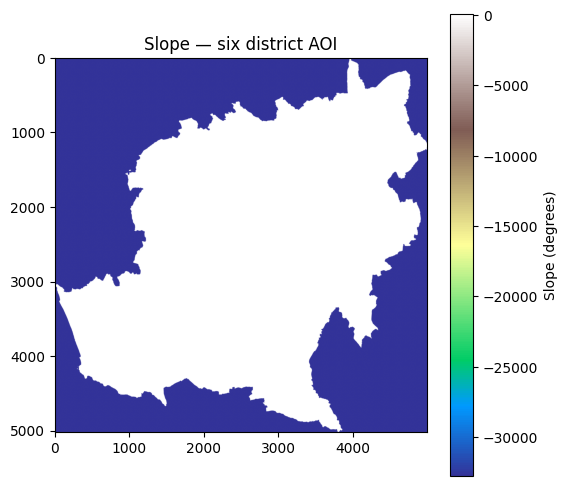

In [20]:
with rasterio.open(DATA_PROCESSED / "slope.tif") as src:
    fig, ax = plt.subplots(figsize=(6, 6))
    im = ax.imshow(src.read(1), cmap="terrain")
    plt.colorbar(im, label="Slope (degrees)")
    ax.set_title("Slope — six district AOI")
plt.show()

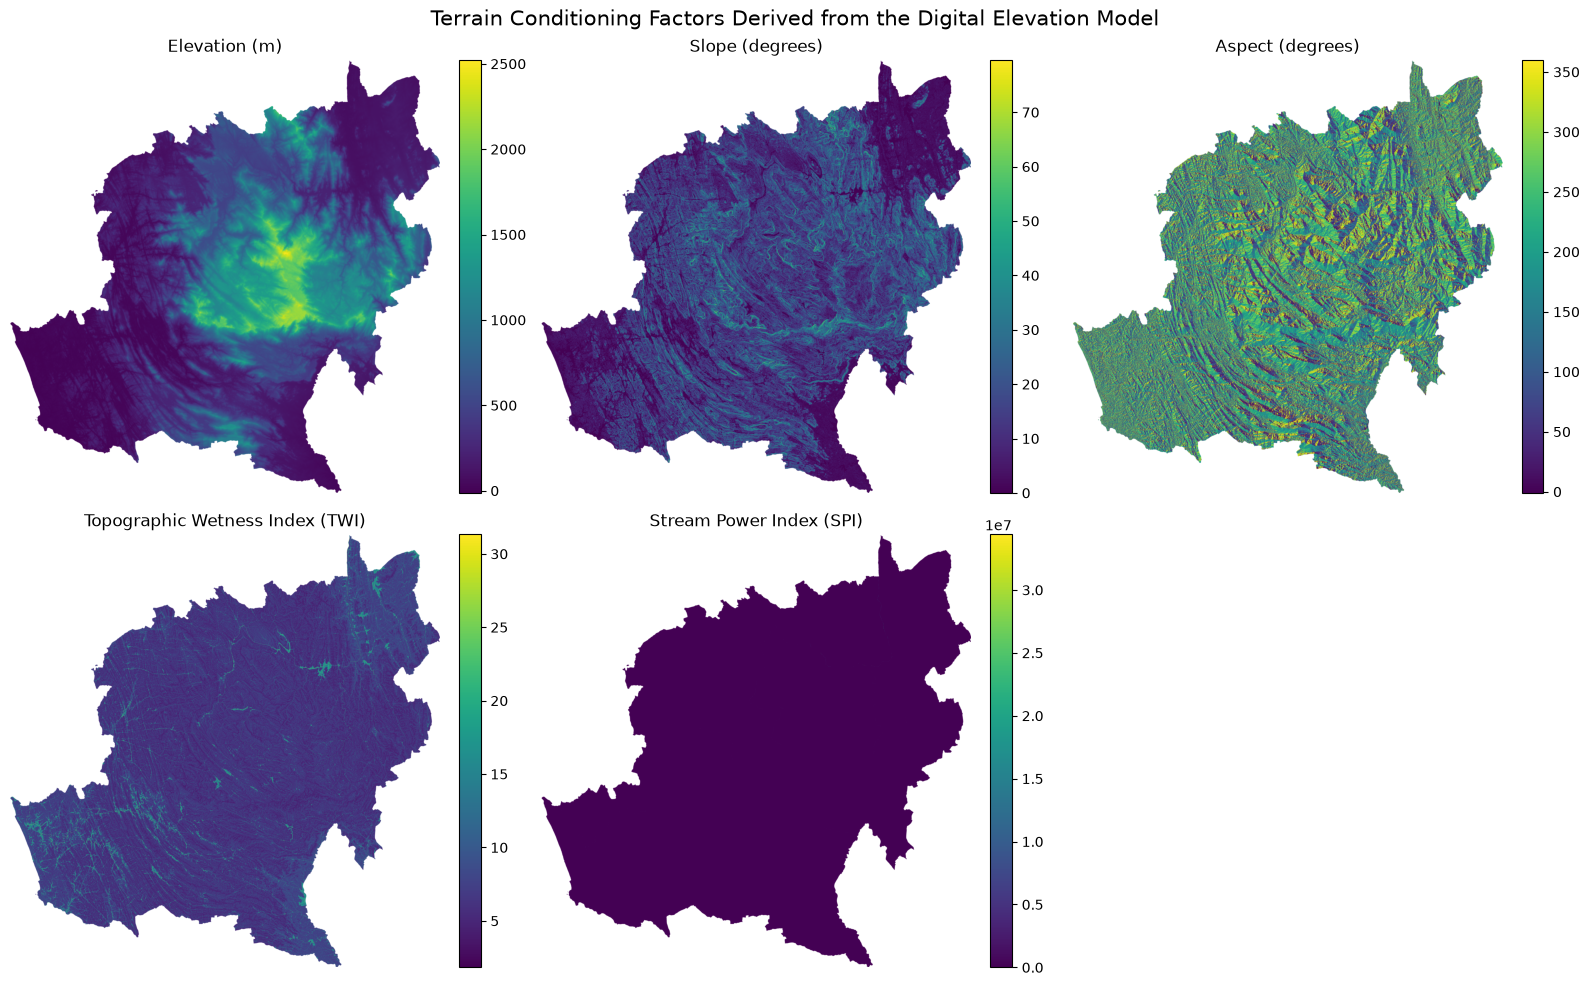

In [ ]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

DATA_PROCESSED = Path("../data/processed")

terrain_files = {
    "Elevation (m)": "dem_utm.tif",
    "Slope (degrees)": "slope.tif",
    "Aspect (degrees)": "aspect.tif",
    "Topographic Wetness Index (TWI)": "twi.tif",
    "Stream Power Index (SPI)": "spi.tif"
}

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for ax, (title, filename) in zip(axes, terrain_files.items()):
    path = DATA_PROCESSED / filename

    with rasterio.open(path) as src:
        data = src.read(1).astype("float32")

        # Remove NoData values
        if src.nodata is not None:
            data[data == src.nodata] = np.nan

    img = ax.imshow(data)

    ax.set_title(title, fontsize=12)
    ax.set_axis_off()

    cbar = fig.colorbar(
        img,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )

# Remove unused sixth panel
axes[-1].axis("off")

plt.suptitle(
    "Terrain Conditioning Factors Derived from the Digital Elevation Model",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "terrain_conditioning_factors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [2]:
from pathlib import Path
import whitebox

DATA_PROCESSED = Path("../data/processed")
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

wbt = whitebox.WhiteboxTools()
wbt.set_working_dir(str(DATA_PROCESSED.resolve()))
wbt.verbose = True

print("WhiteboxTools ready")
print("Working directory:", wbt.work_dir)

WhiteboxTools ready
Working directory: D:\PROJECTS\Landslide_prediction\data\processed


In [3]:
# Generate terrain curvature factors

wbt.plan_curvature(
    "dem_filled.tif",
    "plan_curvature.tif"
)

assert (
    DATA_PROCESSED / "plan_curvature.tif"
).exists(), "Plan curvature generation failed"


wbt.profile_curvature(
    "dem_filled.tif",
    "profile_curvature.tif"
)

assert (
    DATA_PROCESSED / "profile_curvature.tif"
).exists(), "Profile curvature generation failed"

print("Plan curvature and profile curvature ready")

.\whitebox_tools.exe --run="PlanCurvature" --wd="D:\PROJECTS\Landslide_prediction\data\processed" --dem='dem_filled.tif' --output='plan_curvature.tif' -v --compress_rasters=False

****************************
* Welcome to PlanCurvature *
* Powered by WhiteboxTools *
* www.whiteboxgeo.com      *
****************************
Progress: 0%
Progress: 1%
Progress: 2%
Progress: 3%
Progress: 4%
Progress: 5%
Progress: 6%
Progress: 7%
Progress: 8%
Progress: 9%
Progress: 10%
Progress: 11%
Progress: 12%
Progress: 13%
Progress: 14%
Progress: 15%
Progress: 16%
Progress: 17%
Progress: 18%
Progress: 19%
Progress: 20%
Progress: 21%
Progress: 22%
Progress: 23%
Progress: 24%
Progress: 25%
Progress: 26%
Progress: 27%
Progress: 28%
Progress: 29%
Progress: 30%
Progress: 31%
Progress: 32%
Progress: 33%
Progress: 34%
Progress: 35%
Progress: 36%
Progress: 37%
Progress: 38%
Progress: 39%
Progress: 40%
Progress: 41%
Progress: 42%
Progress: 43%
Progress: 44%
Progress: 45%
Progress: 46%
Progress: 47%
Progress: 48%

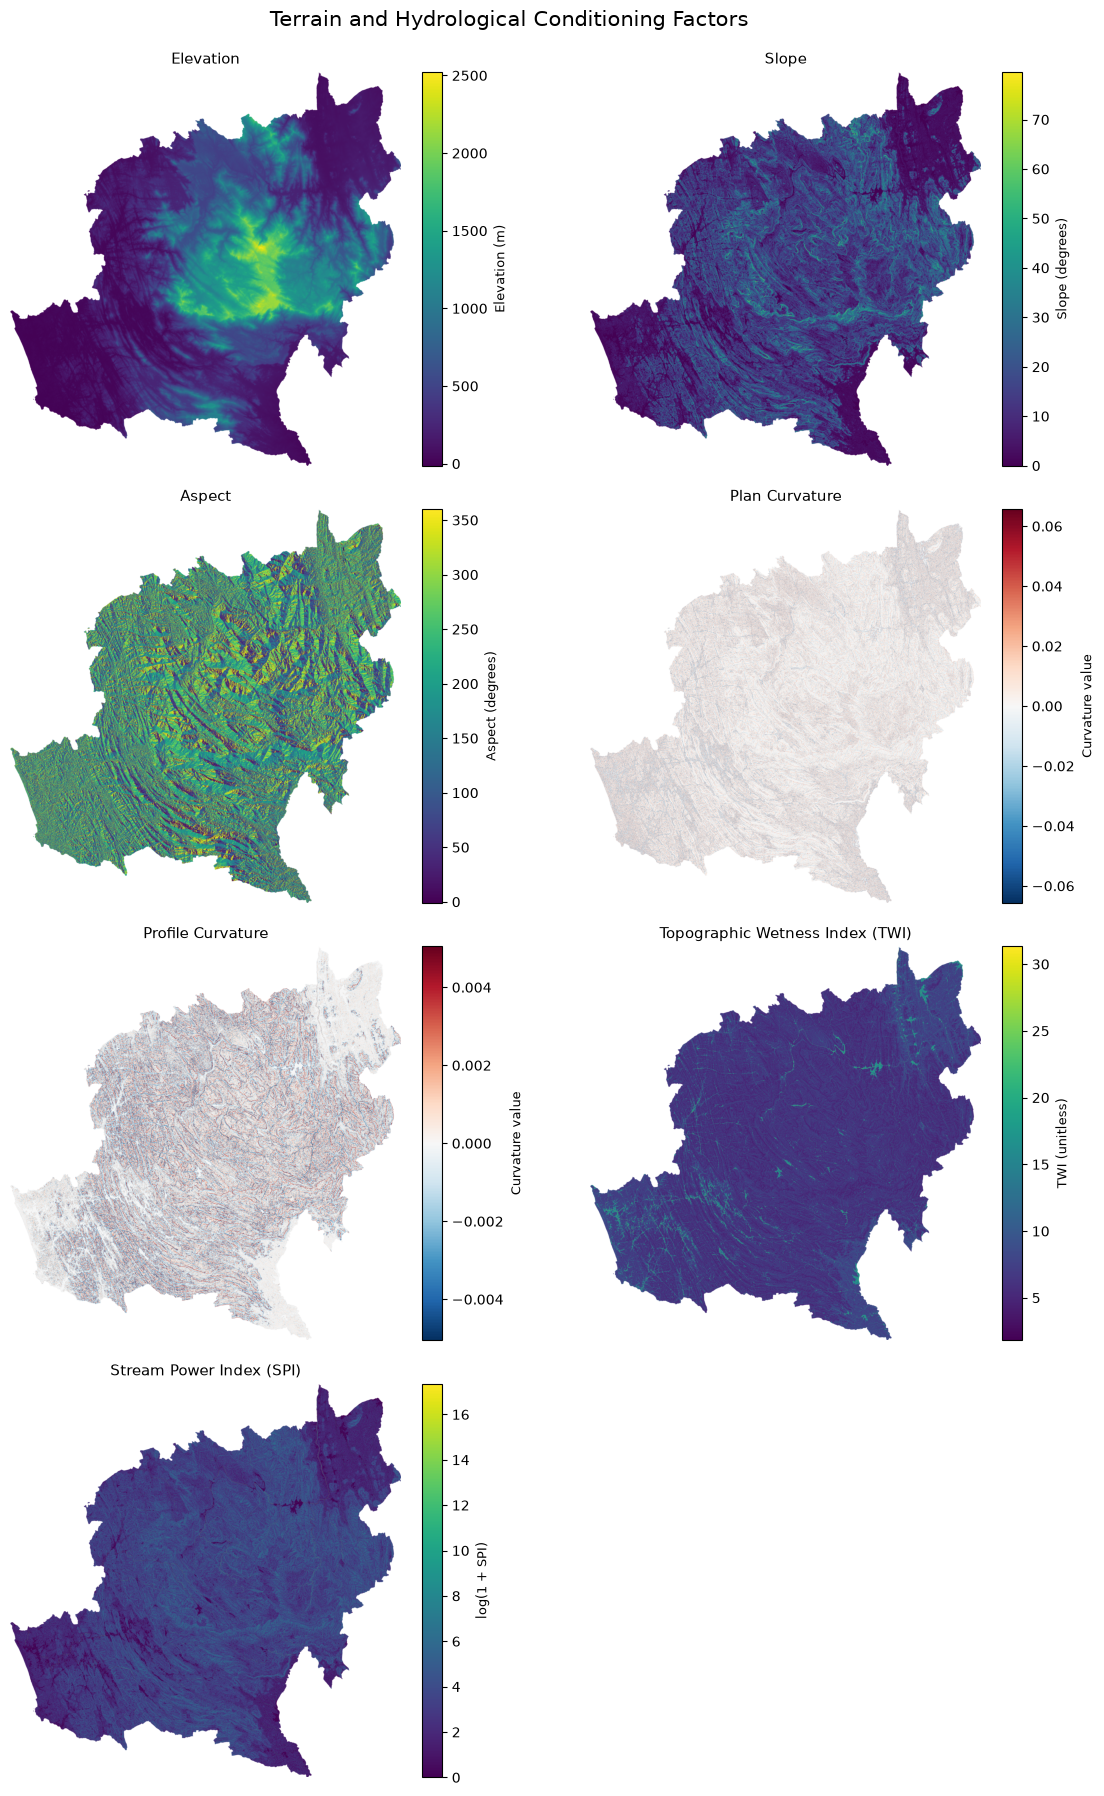

In [5]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.colors import TwoSlopeNorm

DATA_PROCESSED = Path("../data/processed")

terrain_files = {
    "Elevation": {
        "file": "dem_utm.tif",
        "label": "Elevation (m)"
    },
    "Slope": {
        "file": "slope.tif",
        "label": "Slope (degrees)"
    },
    "Aspect": {
        "file": "aspect.tif",
        "label": "Aspect (degrees)"
    },
    "Plan Curvature": {
        "file": "plan_curvature.tif",
        "label": "Curvature value"
    },
    "Profile Curvature": {
        "file": "profile_curvature.tif",
        "label": "Curvature value"
    },
    "Topographic Wetness Index (TWI)": {
        "file": "twi.tif",
        "label": "TWI (unitless)"
    },
    "Stream Power Index (SPI)": {
        "file": "spi.tif",
        "label": "log(1 + SPI)"
    }
}

fig, axes = plt.subplots(4, 2, figsize=(12, 18))
axes = axes.flatten()

for ax, (title, info) in zip(axes, terrain_files.items()):

    path = DATA_PROCESSED / info["file"]

    with rasterio.open(path) as src:
        data = src.read(1).astype("float32")

        if src.nodata is not None:
            data[data == src.nodata] = np.nan

        data[~np.isfinite(data)] = np.nan

    # SPI: log scale for visualization
    if title == "Stream Power Index (SPI)":
        display_data = np.log1p(np.maximum(data, 0))

        img = ax.imshow(
            display_data,
            cmap="viridis"
        )

    # Curvature: diverging scale centered at zero
    elif "Curvature" in title:
        vmax = np.nanpercentile(np.abs(data), 98)

        img = ax.imshow(
            data,
            cmap="RdBu_r",
            norm=TwoSlopeNorm(
                vmin=-vmax,
                vcenter=0,
                vmax=vmax
            )
        )

    # Other factors
    else:
        img = ax.imshow(
            data,
            cmap="viridis"
        )

    ax.set_title(title, fontsize=11)
    ax.set_axis_off()

    cbar = fig.colorbar(
        img,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )

    cbar.set_label(info["label"], fontsize=9)

# Hide unused eighth panel
axes[-1].axis("off")

plt.suptitle(
    "Terrain and Hydrological Conditioning Factors",
    fontsize=15,
    y=0.995
)

plt.tight_layout()

plt.savefig(
    "terrain_conditioning_factors_complete.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()